# 3. Methane: Visual Input and Output

A **hand crafted** input file is a powerful thing. We can set it up exactly as we like. But there is another way. We can use various helper programs that enable the **visual creation** of a molecule and automatic generation of *GAMESS* input files. These files will often need further editing to get what you want out of *GAMESS* but, after we start using molecules larger than benzene, we will appreciate the **graphical interface** (and curse it often).

When interpreting the **output file**, we can evaluate energies and bond lengths and angles easily. But **visualization** of the whole molecule will help see the **relationships** between distant atoms and also quickly identify structures that optimized to a nonsense answer. In addition, we can now interpret more mathematical aspects of the output like bond **vibrations** and mathematical **surfaces** that represent electron density and **molecular orbital** functions.

The two applications that we will use are *MacMolPlt* and *Avogadro*. Both have different **strengths** and we will get to know them both. In this exercise, we will use *MacMolPlt* to build the molecule and to look at the results. In between, this notebook runs *GAMESS* and reads the numbers out of the log files with *Python*.

## Learning Goals

In this exercise, we will **accomplish** the following…

1.	Use *MacMolPlt* to **build** molecules, generate input files and interpret results.
2.	Use *Python* to **submit** jobs to *GAMESS* and check the results.
3.	Use *MacMolPlt* to generate graphical **images** of the molecule and surfaces that represent electron density and **molecular orbitals**.
4.	Identify the molecular orbitals that are most closely associated with the **bonding local molecular orbitals** and lone pair local MOs. How do you think about bonds and electronic structure? Do you think using **local** MOs that align with the Lewis structure or do you think using the molecular orbitals that describe the combined interactions of all atomic orbitals.

:::{note} Mac users: after a restart
macOS resets the shared-memory limits every time you restart. If a *GAMESS* job stops with a fatal error and the `.log` file shows `shmget returned an error`, set the limits again (see [Raise shared-memory limits](#shared-memory-limits) in [](1D-CompileInstruction2024.md)).
:::

### Settings

Run this cell first. It loads the book's helper module, `gamess_tools.py`, which finds *GAMESS* using the location you set in `gamess_settings.py` on the [setup page](1_Setup.ipynb). The `.log` files are written into the `runs/` folder next to this notebook. That is the folder to look in when you open a result in *MacMolPlt*.

In [1]:
# ===== SETTINGS =========================================================
# Your GAMESS location is set ONCE, in gamess_settings.py (next to this
# notebook). Edit that file, save it, and restart the kernel.
from pathlib import Path
import numpy as np
import gamess_tools as gt

INPUTS = Path("inputs")     # input files that come with the book
RUNS = Path("runs")         # where log files and new input files are written
RUNS.mkdir(exist_ok=True)

HARTREE_TO_KJMOL = 2625.5   # 1 hartree = 2625.5 kJ/mol
# ========================================================================

## Making Methane

Open your copy of *wxMacMolPlt* and **navigate** to the build menu: `Builder` &rarr; `Show Build Tools`. Select carbon with a coordination number of 4 and click in the empty window. Then select `Builder` &rarr; `Add Hydrogens` to complete your structure of methane. Efforts to enforce symmetry on files created by *MacMolPlt* often fail and manual creation of files that use symmetry is preferred. *GAMESS* requires perfection when you are declaring symmetry. As a result, we will **not use** symmetry in this calculation.

```{note}
*MacMolPlt* has a **symmetry builder** function that can apply the point group as you build the molecule. We will discuss it later.
```

Select `Subwindow` &rarr; `Input Builder` to start making an **input file** for *GAMESS*. In the `Basis` window select 6-311G for the basis set. Set “1” for `D and light atom polarization functions` (this is the “d,p” in the 6-311G(d,p) basis set.) Check the `Diffuse l-shell` and `s-shell` options (this is the “++” in 6-311G(d,p)++.)

In the `Control` window select `Run Type: Optimization` and also select `Localization Method: Edmiston-Ruedenberg`. The localization method will command *GAMESS* to write **information** into the output file that can be used to make **local** bonding molecular orbitals (we will be using them very soon in this exercise).

In the `Data` window make sure that the coordinate option is set to `Unique Cartesian`. Set the `symmetry point group` to *C<sub>1</sub>*. With *C<sub>1</sub>*, every atom will be unique as we are not declaring symmetry.
In the `Misc Prefs` window set the *MacMolPlt* option. This will **result** in data written into the output file that helps *MacMolPlt* interpret the results.

In the `Stat. Point` window we can set the number of steps to a higher number than 20. We will use 20 for now.

Click on the `Edit and Save` button and you will get a text window with the generated input file. You can make changes now or you can use a text editor later. Save the file as `methane.inp` in the `inputs/` folder next to this notebook. Below is the file as saved by *MacMolPlt* (the book comes with a copy, so you can carry on even without *MacMolPlt*).

```{literalinclude} inputs/methane.inp
:label: amethane-inp
:caption: inputs/methane.inp
:linenos: True
```

## Running the Job from *Python*

We submit the job with one line of *Python*. The function `gt.run_gamess()` runs *GAMESS* and waits until it is finished. The optimization in the 6-311G(d,p)++ basis without symmetry takes a few seconds.

In [2]:
methane_log = gt.run_gamess(INPUTS / "methane.inp")

methane: finished normally (methane.log)


**Look** at the end of the file for the phrase `GAMESS TERMINATED NORMALLY`. `run_gamess()` already did this for us and printed "finished normally"; the function `gt.terminated_normally()` does the same check whenever we need it. If there was an error, trouble shoot the input file and **try again**.

Next, find the `EQUILIBRIUM GEOMETRY LOCATED` statement, record the energy and check the new optimized coordinates for sanity.

In [3]:
print("terminated normally:", gt.terminated_normally(methane_log))
gt.excerpt(methane_log, "EQUILIBRIUM GEOMETRY LOCATED", after=8)

print(f"\nFinal energy: {gt.final_energy(methane_log):.10f} hartree")

terminated normally: True
 1700        ***** EQUILIBRIUM GEOMETRY LOCATED *****
 1701   COORDINATES OF ALL ATOMS ARE (ANGS)
 1702     ATOM   CHARGE       X              Y              Z
 1703   ------------------------------------------------------------
 1704   C           6.0  -0.0000000001   0.0000000004  -0.0000000001
 1705   H           1.0   0.6260104084  -0.6260104082  -0.6260104088
 1706   H           1.0  -0.6260104087   0.6260104081  -0.6260104093
 1707   H           1.0  -0.6260104082  -0.6260104081   0.6260104090
 1708   H           1.0   0.6260104086   0.6260104079   0.6260104093

Final energy: -40.2091691917 hartree


Are the coordinates sane? All four C–H bonds and all six H–C–H angles of methane should be the same. *Python* can check every one of them from the final geometry (atom 1 is carbon, atoms 2 to 5 are hydrogens).

In [4]:
from itertools import combinations

geom = gt.final_geometry(methane_log)
print("C-H bond lengths (Å):", [round(gt.distance(geom, 1, h), 4) for h in range(2, 6)])
print("H-C-H angles (°):    ", [round(gt.angle(geom, a, 1, b), 2)
                                for a, b in combinations(range(2, 6), 2)])

C-H bond lengths (Å): [1.0843, 1.0843, 1.0843, 1.0843]
H-C-H angles (°):     [109.47, 109.47, 109.47, 109.47, 109.47, 109.47]


The structure is a perfect tetrahedron (109.47&deg;), even though we did not ask for any symmetry. The optimization found it on its own because we started close to it.

## Viewing in *MacMolPlt*

Use *MacMolPlt* to **open** the `runs/methane.log` file that was produced by *GAMESS*. You will see an **image** of the methane molecule. Practice **rotating** it and **zooming** in an out.

We can **measure** lengths and angles in *MacMolPlt*. Click on an atom to select it. Then click on a second atom while holding `[SHIFT]`. Then select `View` &rarr; `Annotations` &rarr; `Display Length`. Do this with any three atoms and select `View` &rarr; `Annotations` &rarr; `Display Angle`. You can **measure** lengths angles and torsions right off the screen. You can **display** atom numbers with `View` &rarr; `Atoms Labels` &rarr; `Atom Number`. **Explore** the menus and see what you can do. Do your measurements agree with the numbers that *Python* calculated above?

You can **save** the image in the window using `File` &rarr; `Export`. Explore the **options** and see what makes the best image file for you. See {numref}`fig1A` for an example.

```{figure} images/Methane_Measured.png
---
width: 250px
name: fig1A
---
*MacMolPlt* view of methane with some annotations added.
```

We can **display** the electron density surface of methane using `Subwindow` &rarr; `Surfaces`. Select `3D Total Electron Density` from the list and chose settings until you get a **picture** like the one in {numref}`fig2A`.

```{figure} images/Methane_surface.png
---
width: 350px
name: fig2A
---
The electron density surface colored according to molecular electrostatic potential (MEP). Can you set the values to make the image look like this?
```

Methane is very **nonpolar** so the MEP will be mostly one color. Molecules with heteroatoms will be more revealing in this regard.

## Molecular Orbitals

We often see **molecular orbital diagrams** in textbooks. Let’s try to make our own for methane.

### Visualizing MOs

Use the `surface` subwindow again and this time select `3D orbital` as the choice. Choose `Molecular Eigenvectors` as the orbital set and then **change settings** until you get an image similar to the one in {numref}`fig3A`.

```{figure} images/Methane_HOMO-nosym.png
---
width: 500px
name: fig3A
---
One of the three degenerate HOMOs of methane. The lack of symmetry in the calculation leads to a lack of symmetry in the orbitals.
```

We see the familiar methane HOMO there but it is not **perfectly** symmetrical. We did not use symmetry in our calculations because input files generated by *MacMolPlt* often fail symmetry requirements.

The pictures are drawn from numbers in the log file. Each molecular orbital is a list of **coefficients**, one for each atomic basis function. `gt.molecular_orbitals()` reads the last set of orbitals in a log file. Here are the orbital energies, with the number of occupied orbitals (the HOMO is the last occupied one) from `gt.occupied_orbitals()`.

In [5]:
mo_c1 = gt.molecular_orbitals(methane_log)
homo = gt.occupied_orbitals(methane_log)

for n in range(homo + 2):
    tag = "HOMO" if n + 1 == homo else ("LUMO" if n + 1 == homo + 1 else "")
    print(f"MO {n + 1:2d}  {mo_c1['energies'][n]:9.4f} hartree  "
          f"symmetry {mo_c1['symmetries'][n]:3s} {tag}")

MO  1   -11.2052 hartree  symmetry A   
MO  2    -0.9451 hartree  symmetry A   
MO  3    -0.5461 hartree  symmetry A   
MO  4    -0.5461 hartree  symmetry A   
MO  5    -0.5461 hartree  symmetry A   HOMO
MO  6     0.0419 hartree  symmetry A   LUMO
MO  7     0.0784 hartree  symmetry A   


Orbitals 3, 4 and 5 have exactly the same energy: they are the three **degenerate** HOMOs. Without symmetry, *GAMESS* labels every orbital simply as `A` (the only label available in *C<sub>1</sub>*).

### *T<sub>d</sub>* Methane

We can **construct** a symmetrical structure of methane using symmetry tools in *MacMolPlt*. However, for now let us do this **manually**. First I will make an AM1 input file for structural **optimization** of *T<sub>d</sub>* methane.

```{literalinclude} inputs/methane_AM1_U.inp
:label: methane_am1_u-inp1
:caption: inputs/methane_AM1_U.inp
:linenos: True
```

In [6]:
methane_am1_log = gt.run_gamess(INPUTS / "methane_AM1_U.inp")
am1_geom = gt.final_geometry(methane_am1_log)
print(f"AM1 C-H bond length: {gt.distance(am1_geom, 1, 2):.4f} Å")

methane_AM1_U: finished normally (methane_AM1_U.log)
AM1 C-H bond length: 1.1116 Å


After submitting it, we have the coordinates optimized at the AM1 level. These can be carried up to an HF/6-311G(d,p)++ optimization, as we did in [chapter 2](2_SmallMolecules.ipynb). The input file below is for the HF/6-311G(d,p)++ **energy** at *T<sub>d</sub>* symmetry and it already holds the HF/6-311G(d,p)++ optimized coordinates. I **added the command** for creating local bonding orbitals (line 2).

```{literalinclude} inputs/methane_6311_U_E.inp
:label: methane_6311_u_e-inp1
:caption: inputs/methane_6311_U_E.inp
:emphasize-lines: 2
:linenos: True
```

The hydrogen sits at 0.6260 Å along each axis, so the C–H bond is $\sqrt{3}\times 0.6260 = 1.0843$ Å. That is the same structure that our *C<sub>1</sub>* optimization found above, so the two calculations describe the same molecule. Only the symmetry declaration is different.

In [7]:
td_log = gt.run_gamess(INPUTS / "methane_6311_U_E.inp")

print(f"C1 optimization, final energy: {gt.final_energy(methane_log):.10f} hartree")
print(f"Td single point energy:        {gt.final_energy(td_log):.10f} hartree")

methane_6311_U_E: finished normally (methane_6311_U_E.log)
C1 optimization, final energy: -40.2091691917 hartree
Td single point energy:        -40.2091691920 hartree


### MOs for *T<sub>d</sub>* Methane

I **opened** the log file (`runs/methane_6311_U_E.log`) in *MacMolPlt* and when I **displayed** the HOMO for this symmetrical calculation the orbitals were perfect. It should be noted that both sets of MOs were really the same. It is exactly the same math. The less symmetrical image was produced using axes that did not perfectly align with the **elements of symmetry** of the orbitals. However, just because there was a little more *x* and a little less *y* does not change the way the orbitals behave. It’s just how the **picture** is calculated, the underlying math of the MO never changes. The new improved MO image is presented in {numref}`fig4A`.

```{figure} images/Methane_HOMO-sym.png
---
width: 250px
name: fig4A
---
The HOMO of methane generated from a calculation that used the *T<sub>d</sub>* symmetry requirement.
```

We can see "a little more *x* and a little less *y*" in the numbers. The cell below prints the coefficients of the carbon 2*p* functions (*x*, *y* and *z*) in the three HOMOs from both calculations. (The 6-311G basis has three sets of carbon *p* functions; we print the first set.)

In [8]:
mo_td = gt.molecular_orbitals(td_log)

def carbon_p(mo, orbital):
    # coefficients of the first C X, C Y and C Z basis functions in one orbital
    rows = [mo["labels"].index(f"C 1 {axis}") for axis in "XYZ"]
    return mo["coefficients"][rows, orbital - 1]

for name, mo in [("C1 (no symmetry)", mo_c1), ("Td", mo_td)]:
    print(name)
    for orbital in (3, 4, 5):
        x, y, z = carbon_p(mo, orbital)
        print(f"  MO {orbital} ({mo['symmetries'][orbital - 1]:2s}) "
              f"E = {mo['energies'][orbital - 1]:.4f}   x {x:8.4f}  y {y:8.4f}  z {z:8.4f}")

C1 (no symmetry)
  MO 3 (A ) E = -0.5461   x  -0.0594  y   0.0160  z  -0.1795
  MO 4 (A ) E = -0.5461   x  -0.1790  y   0.0163  z   0.0607
  MO 5 (A ) E = -0.5461   x  -0.0205  y  -0.1884  z  -0.0100
Td
  MO 3 (T2) E = -0.5461   x   0.1897  y  -0.0000  z  -0.0000
  MO 4 (T2) E = -0.5461   x  -0.0000  y   0.1897  z  -0.0000
  MO 5 (T2) E = -0.5461   x  -0.0000  y  -0.0000  z   0.1897


With *T<sub>d</sub>* symmetry each HOMO is built from just one carbon *p* orbital (*x*, *y* or *z*), so each picture lines up with the axes. Without symmetry, each HOMO is a mixture of all three. Any mixture of degenerate orbitals is an equally good answer, so the energies are identical. Only the picture changes.

### Local Bonding Orbitals

We are used to describing **bonds** around second-row elements like carbon as *sp*, *sp<sup>2</sup>*, or *sp<sup>3</sup>*. A *sp<sup>3</sup>* bonding MO can be constructed from the overlap of the carbon *sp<sup>3</sup>* AO and the hydrogens *s*-orbital. This would be a **simple model** that describes the electron pair for that bond (not really) and relates more directly to **Lewis structure** (if you prefer stick drawings to the truth of math.) In the `Subwindow` &rarr; `Surfaces` window choose the `3D Orbital` option and then choose the `Localized Orbitals` option from the `Orbital Set` menu. Select one of the orbitals and then **choose** settings that produce an image similar to what you see in {numref}`fig5A`. Have fun and try lots of settings.

```{figure} images/Methane_LOCAL_4.png
---
width: 350px
name: fig5A
---
A local bonding MO for the C–H bond in methane.
```

The localized orbitals are printed in the log file after the heading `EDMISTON-RUEDENBERG ENERGY LOCALIZED ORBITALS`. `gt.localized_orbitals()` reads them. Orbital 1 is the carbon 1*s* core, which is left alone (*frozen*). For each of the other four we can ask *Python* which hydrogen has the largest share of the orbital: each localized orbital belongs to one C–H bond.

In [9]:
labels, lmo = gt.localized_orbitals(td_log)
atoms = sorted({" ".join(label.split()[:2]) for label in labels},
               key=lambda a: int(a.split()[1]))          # "C 1", "H 2", ...

for orbital in range(lmo.shape[1]):
    # sum of squared coefficients on each atom: a rough "share" of the orbital
    share = {atom: sum(lmo[r, orbital] ** 2 for r, label in enumerate(labels)
                       if label.startswith(atom + " "))
             for atom in atoms}
    total = sum(share.values())
    text = "  ".join(f"{atom}: {100 * s / total:4.1f}%" for atom, s in share.items())
    print(f"LMO {orbital + 1}   {text}")

LMO 1   C 1: 100.0%  H 2:  0.0%  H 3:  0.0%  H 4:  0.0%  H 5:  0.0%
LMO 2   C 1: 58.9%  H 2:  0.6%  H 3:  0.6%  H 4:  0.6%  H 5: 39.2%
LMO 3   C 1: 58.9%  H 2:  0.6%  H 3: 39.2%  H 4:  0.6%  H 5:  0.6%
LMO 4   C 1: 58.9%  H 2: 39.2%  H 3:  0.6%  H 4:  0.6%  H 5:  0.6%
LMO 5   C 1: 58.9%  H 2:  0.6%  H 3:  0.6%  H 4: 39.2%  H 5:  0.6%


LMO 1 is all carbon (the 1*s* core). Each of the LMOs 2 to 5 is shared between the carbon and **one** hydrogen: one localized orbital per C–H bond, just like the Lewis structure.

Which seems **easier** to interpret when explaining the C–H bond: the true MO or a local bonding MO model? When you are **constructing** a MO diagram using hybrid atomic orbitals, you will naturally be constructing the local bonding MOs from *sp<sup>3</sup>* carbon AOs and hydrogen *s*-AOs. You can then further **combine** these local MOs to make the orthogonal MOs that actually describe the electronic structure.

*GAMESS* prints the numbers that show this combination: the `FOCK OPERATOR FOR THE LOCALIZED ORBITALS`. Its diagonal holds the energy of each local C–H orbital, and the off-diagonal numbers tell us how strongly two local orbitals interact. `gt.localized_fock()` reads it.

In [10]:
fock = gt.localized_fock(td_log)
np.set_printoptions(precision=4, suppress=True)
print("Fock matrix in the four local C-H orbitals (hartree):")
print(fock)

combined = np.linalg.eigvalsh(fock)     # mix the local orbitals: diagonalize
print("\nEnergies after mixing the local orbitals:", combined.round(4))
print("Canonical MO energies 2-5 from GAMESS:   ", np.array(mo_td["energies"][1:5]))

Fock matrix in the four local C-H orbitals (hartree):
[[-0.6459  0.0997  0.0997 -0.0997]
 [ 0.0997 -0.6459 -0.0997  0.0997]
 [ 0.0997 -0.0997 -0.6459  0.0997]
 [-0.0997  0.0997  0.0997 -0.6459]]

Energies after mixing the local orbitals: [-0.9451 -0.5461 -0.5461 -0.5461]
Canonical MO energies 2-5 from GAMESS:    [-0.9451 -0.5461 -0.5461 -0.5461]


Every local C–H orbital has the same energy (–0.646 hartree), but they are not independent: each one interacts with the other three (–0.100 hartree). Mixing the four local orbitals (diagonalizing the matrix) gives back exactly the canonical molecular orbitals: one low-lying *a*<sub>1</sub> orbital at –0.945 hartree (all four local orbitals in phase) and the three degenerate *t*<sub>2</sub> HOMOs at –0.546 hartree. The local and the delocalized pictures are the **same** electrons described in two different ways.

## A Molecular Orbital Diagram

In this exercise, you will be asked to **construct** MO diagrams with visualized MOs and local bonding MOs. Here is a pair of molecular orbital **diagrams**. {numref}`fig6A` uses the atomic orbitals to make the true molecular orbitals for the molecule. However it is often **more informative** to consider local molecular orbitals as presented in {numref}`fig7A`.

```{figure} images/MOs_Diagram_Methane1.png
---
width: 500px
name: fig6A
---
MO diagram for methane.
```

```{figure} images/MOs_Diagram_Methane2.png
---
width: 700px
name: fig7A
---
MO diagram using the local molecular orbital model.
```

*Python* can draw the energy-level part of such a diagram straight from the log file. The plot below puts the four valence local orbitals (left) next to the valence canonical MOs and the lowest empty MO, the LUMO (right). Use it as the skeleton of your own diagram and add the *MacMolPlt* orbital pictures beside the levels.

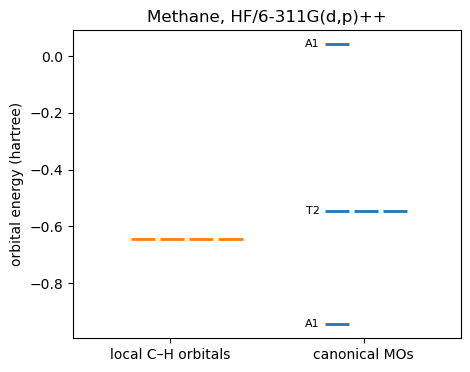

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 4))

def levels(x, energies, color, labels=None):
    # draw each energy as a short horizontal line; spread degenerate levels sideways
    seen = {}
    for i, e in enumerate(energies):
        k = seen.setdefault(round(e, 3), 0)
        seen[round(e, 3)] += 1
        ax.hlines(e, x + 0.3 * k, x + 0.3 * k + 0.25, color=color, lw=2)
        if labels and k == 0:
            ax.text(x - 0.05, e, labels[i], ha="right", va="center", fontsize=8)

levels(0, np.diag(fock), "tab:orange")
canonical = mo_td["energies"][1:homo + 1]               # valence MOs 2 to 5 and the LUMO
levels(2, canonical, "tab:blue", mo_td["symmetries"][1:homo + 1])

ax.set_xticks([0.4, 2.4], ["local C–H orbitals", "canonical MOs"])
ax.set_ylabel("orbital energy (hartree)")
ax.set_xlim(-0.6, 3.4)
ax.set_title("Methane, HF/6-311G(d,p)++")
plt.show()

## The Multiverse

The *T<sub>d</sub>* symmetry **enforces** that the hydrogens are each in one of the octants of 3D space. This means that the cardinal planes are not through any of the hydrogen atoms. If you considered that the four hydrogens were each at corners of the cube, then the planes are slicing through the faces of the cube. This is why all three of the degenerate orbitals are **identical** in appearance.

Your textbook may present **different** images of these orbitals. They are exactly the **same** orbitals, just with different placements of the cardinal planes w.r.t. the bonds. We used *C<sub>3v</sub>* symmetry for the ammonia molecule and, if we had used it with the methane *Z-matrix* that was created by modifying the ammonia *Z-matrix*, it would have worked just fine. The *C<sub>3v</sub>* symmetry requires that one of the four C–H bonds be along the *z*-axis. This means that two C–H bonds will be in a cardinal plane. The three degenerate orbitals all appear different because they each have a different relationship to the symmetry space. Despite this, they are identical. If orbitals have exactly the **same** energy then they are **identical**. The *C<sub>3v</sub>* arrangement is perhaps the most useful for interpreting a reaction. A hydrogen abstraction by a radical will occur by the radical approaching along a **bond axis**. Adding that element will reduce the symmetry to *C<sub>3v</sub>* from *T<sub>d</sub>*. The molecular orbital that **aligns** with the *z*-axis best describes the **frontier orbital** that will guide the reaction as the atoms approach each other.

Another **option** is to use the *C<sub>2v</sub>* symmetry space. This will result in two separate pairs of C–H bonds being in cardinal planes. As a result two of the orbital images will appear identical with a third image being with a plane placed perpendicular to the other two. Again, it must be emphasized that all three degenerate molecular orbitals are **identical**.

I prefer the *T<sub>d</sub>* MO set since it does emphasize the idea that all three degenerate MOs are **identical**. (How many times have I said that already?) The *C<sub>3v</sub>* set is best for explaining frontier orbital interactions with an **approaching** radical, but I prefer using the idea of a **local** bonding C–H &sigma;-orbital when discussing a reaction with a C–H bond. **Compare** the local orbital with the *z*-axis MO and see how they are both great for discussing **frontier** molecular orbital theory. The **local** orbital is far easier to use when we want to invoke the anti-bonding orbital that an approaching radical will actually be interacting with.

You will be exploring these ideas in the exercise supported by this discussion. Good luck.

## Summary

We have used *MacMolPlt* to **build** a small molecule and generate an input file for *GAMESS*. We have **submitted** that file to *GAMESS* from *Python*.

We have used *Python* and *MacMolPlt* to **measure** bond lengths and angles and *MacMolPlt* to **visualize** the molecular orbital data generated by *GAMESS*. We have exported the **images** in our favourite graphic file format. We have read the orbital energies and coefficients with *Python* and seen that the local C–H orbitals combine to give the canonical molecular orbitals.

Where will we go from here? Open the instructions for the exercise that this discussion supports. Have fun.

## Exercise

Read the discussion above and then try the following activities.

### The Activities

You will have HF/6-311G(d,p)++ optimized structures for methane (*T<sub>d</sub>*). You also have the same results for ammonia (*C<sub>3v</sub>*) and water (*C<sub>2v</sub>*) from the [previous exercise](2_SmallMolecules.ipynb). **Use** the data for those structures to perform an energy (or optimization) calculation and **add** the local orbital command (`LOCAL=RUEDNBRG`) to the `$CONTRL` group.

````{tip}
Run [chapter 2](2_SmallMolecules.ipynb) to write the result files for water and ammonia for you.
````

Use the result file with *MacMolPlt* to **visualize** the bonding molecular orbitals and the localized bonding orbitals. Are there degenerate sets in the molecular orbitals? Do any local orbitals resemble lone pairs? Do any of the MOs seem more closely related to lone pairs or more closely related to bonds? What are the relative energies of these MO sets and do the energies fit with expectations? (`gt.molecular_orbitals()` and `gt.localized_fock()` give you the energies.)

**Construct** input files for methane using *C<sub>3v</sub>* and *C<sub>2v</sub>* symmetry and **compare** the shapes of these versions of the orbitals to those in ammonia and water. What similarities and differences do you observe?

### The Report

**Create** a ONE-PAGE document summarizing your results. Create **images** for each of the three molecules: methane, water, and ammonia. **Include** bond length and angles in the images. Create images of the molecules with the electron density surface colored by electrostatic potential. **Discuss** the reasons for different bond lengths and angles using VSEPR theory.

Create a SECOND ONE-PAGE document with images of local and molecular bonding orbitals for all three molecules. **Identify** which orbitals in each set best represent lone pairs and which best represent bonds to hydrogen atoms.

Create a THIRD ONE-PAGE document that presents the images of the methane **molecular orbitals** using *C<sub>3v</sub>* and *C<sub>2v</sub>* symmetry. **Compare** these with the corresponding orbitals in ammonia and water.

Include an **appendix** with the text input files used with *GAMESS* for all the above.

In all your discussions be brief, but consider the questions raised above. Do your best to make the document in a clear and **professional** style.

## AI Statement

This page was converted from the original Markdown page `3_Visual_Input.md` to a *Jupyter* notebook with the help of Claude (Anthropic), following the author's instructions.

- **Original text kept (about 80 %).** The introduction, the *MacMolPlt* building, viewing, measuring and surface instructions, the discussion of symmetric and non-symmetric MOs, local bonding orbitals, the MO diagrams, "The Multiverse", the summary and the exercise are the author's words, as are all figures and the three input files. Small edits: typos fixed, figure captions tidied, and the exercise now says the `LOCAL` keyword belongs in `$CONTRL` (the original said `$SYSTEM`).
- **Written by AI.** The settings cell, all code cells and the paragraphs that introduce them; the geometry sanity check; the comparison of carbon *p* coefficients in the *C<sub>1</sub>* and *T<sub>d</sub>* HOMOs; the atom-share table for the localized orbitals; the Fock-matrix demonstration that mixing the local C–H orbitals gives the canonical MOs; the energy-level plot; the exercise tip; and the helpers `occupied_orbitals`, `molecular_orbitals`, `localized_orbitals` and `localized_fock` in `gamess_tools.py`.
- **Changed workflow.** Jobs are run with `run_gamess()` instead of *GamessQ*, and the log file is checked by *Python* instead of by eye. The text now states that the *T<sub>d</sub>* energy file holds HF/6-311G(d,p)++ optimized coordinates (the original said AM1). *MacMolPlt* is still used to build the molecule and to draw the orbitals.
- **GamessQ removed.** At the author's request, the sentences that compared each step with the original book's use of *GamessQ* were shortened to describe only the *Python* step.